# Water Potability — Part 3: Model Design, Training, and Evaluation

**Student Name:** Joel Elizee  
**Student ID:** joeeli7267

**Analytical goals from Parts 1 and 2:** (1) classify potable vs. non-potable samples; (2) predict pH from other chemistry measurements; (3) cluster water samples into quality profiles.

This notebook uses **scikit-learn**, which is explicitly permitted as an alternative to TensorFlow. All preprocessing is learned from **training data only** to prevent data leakage. The same 80/20 split is reused, and the held-out test portion is evaluated only after models are finalized. Place `water_potability.csv` beside this notebook before running.

**Note:** These are exploratory models, not validated public-health drinking-water tests. A classifier's predictions are not proof of potability.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, mean_absolute_error,
                             mean_squared_error, r2_score, silhouette_score)
SEED = 42
FIGS = Path('ml_figures')
FIGS.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid')
df = pd.read_csv('water_potability.csv')
print('Rows, columns:', df.shape)
print('Missing values by column:\n', df.isna().sum().to_string())
print('Class counts:\n', df.Potability.value_counts().sort_index().to_string())

Rows, columns: (3276, 10)
Missing values by column:
 ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
Class counts:
 Potability
0    1998
1    1278


## 1. Hold-out design and preprocessing

We reserve **20% for testing** with `random_state=42`, stratified by the binary potability label. The remaining 80% is the training subset. Numeric predictors are median-imputed for missing values. **StandardScaler** is used for K-means (distance-based); random forests do not require scaling because their splits are based on order thresholds. No categorical predictor variables exist, so one-hot encoding is not applicable.

Because pH is the regression target, **rows with missing pH are excluded from the regression task** rather than inventing target labels. For classification/clustering, missing pH values remain eligible for median imputation.

In [2]:
features = df.drop(columns='Potability').columns.tolist()
train_idx, test_idx = train_test_split(df.index, test_size=0.20, random_state=SEED, stratify=df['Potability'])
train_df, test_df = df.loc[train_idx].copy(), df.loc[test_idx].copy()
print('Shared split:', len(train_df), 'train,', len(test_df), 'test')
print('Training label proportions:', train_df['Potability'].value_counts(normalize=True).round(3).to_dict())

Shared split: 2620 train, 656 test
Training label proportions: {0: 0.61, 1: 0.39}


## 2. Classification: predict potability

**Algorithm:** Random Forest Classifier — handles nonlinearities and mixed-scale chemical variables, and provides feature importances. **Initial hyperparameters:** `n_estimators=120` balances stability with runtime; `max_depth=8` limits overly complex trees; `min_samples_leaf=4` reduces variance from small leaves; `class_weight='balanced'` compensates for the unequal target classes; seed 42 ensures reproducibility.

**Training objective:** decision trees split to reduce Gini impurity; the forest averages votes (it has no neural-network compilation or activation function). **Metrics:** accuracy, precision, recall, F1, and confusion matrix. Recall for potable samples is informative, but **false potable predictions** are particularly concerning for safety.

Accuracy               0.6616
Precision (potable)    0.5895
Recall (potable)       0.4375
F1 (potable)           0.5022
Training accuracy      0.8447
Confusion matrix [[TN, FP], [FN, TP]]:
 [[322  78]
 [144 112]]


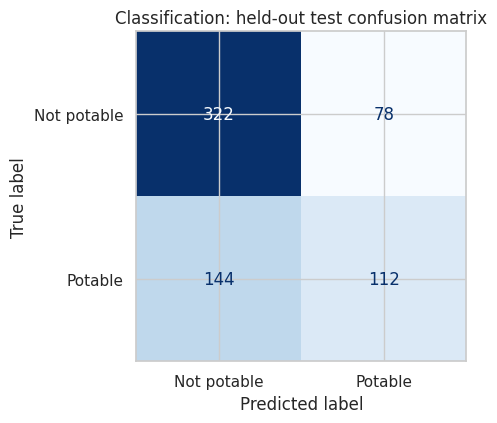

In [3]:
clf = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('model', RandomForestClassifier(n_estimators=120, max_depth=8, min_samples_leaf=4,
                                     class_weight='balanced', random_state=SEED, n_jobs=-1))
])
X_train, X_test = train_df[features], test_df[features]
y_train, y_test = train_df['Potability'], test_df['Potability']
clf.fit(X_train, y_train)
pred_class = clf.predict(X_test)
class_metrics = {
    'Accuracy': accuracy_score(y_test, pred_class),
    'Precision (potable)': precision_score(y_test, pred_class, zero_division=0),
    'Recall (potable)': recall_score(y_test, pred_class, zero_division=0),
    'F1 (potable)': f1_score(y_test, pred_class, zero_division=0),
    'Training accuracy': accuracy_score(y_train, clf.predict(X_train))
}
print(pd.Series(class_metrics).round(4).to_string())
print('Confusion matrix [[TN, FP], [FN, TP]]:\n', confusion_matrix(y_test, pred_class))
fig, ax = plt.subplots(figsize=(5.5,4.4))
ConfusionMatrixDisplay.from_predictions(y_test, pred_class, display_labels=['Not potable', 'Potable'],
                                         cmap='Blues', ax=ax, colorbar=False)
ax.set_title('Classification: held-out test confusion matrix')
fig.tight_layout(); fig.savefig(FIGS/'classification_confusion.png', dpi=170); plt.show()

### Classification training diagnostics

Forests have **no epoch-based loss history**, so we monitor training and test accuracy and calculate the difference as an overfitting check. The held-out set is not used to tune any hyperparameters. Feature importance is useful for interpretation, but should not be treated as causal evidence.

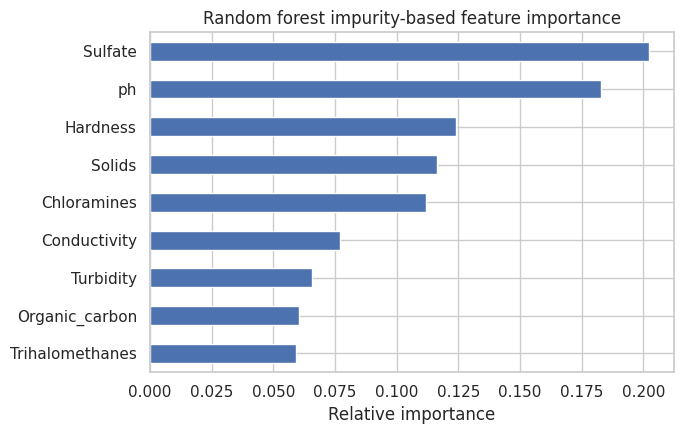

Train-test accuracy gap: 0.1831


In [4]:
importance = pd.Series(clf.named_steps['model'].feature_importances_, index=features).sort_values()
fig, ax = plt.subplots(figsize=(7,4.5)); importance.plot.barh(ax=ax)
ax.set_title('Random forest impurity-based feature importance'); ax.set_xlabel('Relative importance')
fig.tight_layout();fig.savefig(FIGS/'classification_importance.png',dpi=170);plt.show()
print('Train-test accuracy gap:', round(class_metrics['Training accuracy'] - class_metrics['Accuracy'], 4))

## 3. Regression: estimate pH

**Algorithm:** Random Forest Regressor, selected for nonlinear chemical relationships and resilience to differently scaled predictors. **Initial hyperparameters:** `n_estimators=120` for stable averages; `max_depth=9` restricts tree complexity; `min_samples_leaf=4` discourages fits to tiny groups; seed 42 for repeatability. The training criterion is **squared error**. Evaluate by **MAE** (average error in pH units), **RMSE** (penalizes large misses), and **R²** (explained variance). A negative R² indicates worse test performance than predicting a constant test-set mean.

Valid target rows: 2233 train, 552 test
MAE            1.2253
RMSE           1.6008
R2             0.0031
Training R2    0.3535
Naive train-mean MAE: 1.239


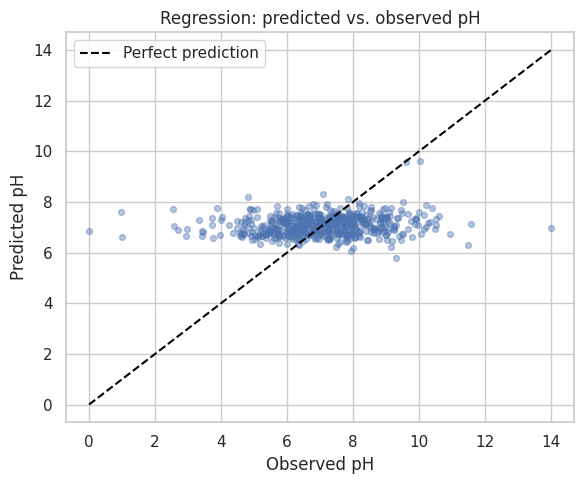

In [5]:
predictors_ph = [c for c in features if c != 'ph']
ph_train = train_df.dropna(subset=['ph'])
ph_test = test_df.dropna(subset=['ph'])
reg = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('model', RandomForestRegressor(n_estimators=120, max_depth=9,
                                    min_samples_leaf=4, random_state=SEED, n_jobs=-1))
])
reg.fit(ph_train[predictors_ph], ph_train['ph'])
y_ph = ph_test['ph']; pred_ph = reg.predict(ph_test[predictors_ph])
reg_metrics = {
    'MAE': mean_absolute_error(y_ph,pred_ph),
    'RMSE': np.sqrt(mean_squared_error(y_ph,pred_ph)),
    'R2': r2_score(y_ph,pred_ph),
    'Training R2': r2_score(ph_train['ph'],reg.predict(ph_train[predictors_ph]))
}
print('Valid target rows:', len(ph_train),'train,',len(ph_test),'test')
print(pd.Series(reg_metrics).round(4).to_string())
print('Naive train-mean MAE:', round(mean_absolute_error(y_ph,np.full(len(y_ph),ph_train['ph'].mean())),4))
fig,ax=plt.subplots(figsize=(6,5));ax.scatter(y_ph,pred_ph,alpha=.4,s=18)
lims=[min(y_ph.min(),pred_ph.min()),max(y_ph.max(),pred_ph.max())]
ax.plot(lims,lims,'--',color='black',label='Perfect prediction')
ax.set(xlabel='Observed pH',ylabel='Predicted pH',title='Regression: predicted vs. observed pH')
ax.legend();fig.tight_layout();fig.savefig(FIGS/'regression_scatter.png',dpi=170);plt.show()

### Regression training diagnostics

Compare in-sample and held-out R² to check generalization. A positive training R² alongside a near-zero or negative test R² suggests that these chemical measurements do not reliably explain pH in the held-out data.

## 4. Clustering: find water-quality profiles

**Algorithm:** K-means, an **unsupervised** learning technique based on minimizing within-cluster squared Euclidean distances (**inertia**). **Initial hyperparameters:** `n_clusters=3` is an interpretable starting point for three potential water-quality profiles, not a proven optimum; `n_init=10` reruns the algorithm to reduce initialization sensitivity; seed 42 for reproducibility. Median imputation followed by standardization ensures all water chemistry measurements contribute in comparable units. `Potability` is excluded from fitting clusters to keep this analysis unsupervised.

K-means is fitted **only on training predictors**; the test split is assigned to learned centroids. **Evaluation:** held-out silhouette score (higher indicates better separation), training/test inertia *per sample* (smaller indicates tighter fit, not necessarily better real-world categories), and cluster sizes. Unlike supervised learning, **accuracy is not defined** without reference cluster labels.

Train silhouette            0.0761
Test silhouette             0.0725
Train inertia per sample    7.7228
Test inertia per sample     7.7885
Train cluster sizes: {0: 920, 1: 911, 2: 789}
Test cluster sizes: {0: 241, 1: 223, 2: 192}


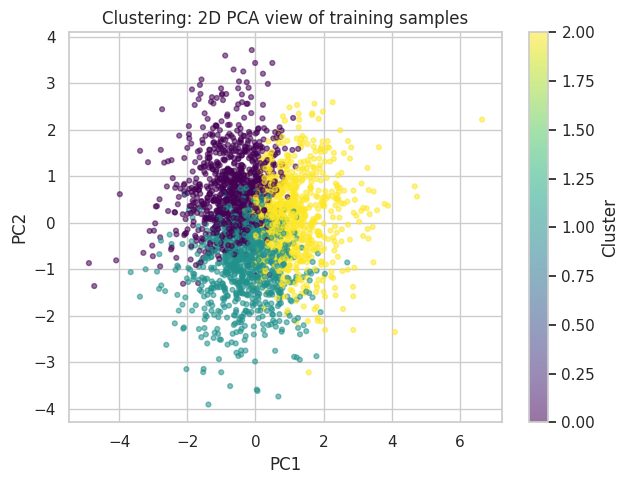

PCA 2D explained variance: 0.262


In [6]:
prep_cluster = Pipeline([('impute',SimpleImputer(strategy='median')),
                         ('scale',StandardScaler())])
Xc_train = prep_cluster.fit_transform(train_df[features])
Xc_test = prep_cluster.transform(test_df[features])
km = KMeans(n_clusters=3, n_init=10, random_state=SEED)
km.fit(Xc_train)
labels_train = km.labels_
labels_test = km.predict(Xc_test)
cluster_metrics = {
    'Train silhouette': silhouette_score(Xc_train,labels_train,sample_size=min(1200,len(Xc_train)),random_state=SEED),
    'Test silhouette': silhouette_score(Xc_test,labels_test),
    'Train inertia per sample': km.inertia_/len(Xc_train),
    'Test inertia per sample': np.sum((Xc_test-km.cluster_centers_[labels_test])**2)/len(Xc_test)
}
print(pd.Series(cluster_metrics).round(4).to_string())
print('Train cluster sizes:', pd.Series(labels_train).value_counts().sort_index().to_dict())
print('Test cluster sizes:', pd.Series(labels_test).value_counts().sort_index().to_dict())
# PCA is applied for illustration only; K-means was fitted on all nine standardized variables.
pca = PCA(n_components=2,random_state=SEED)
proj_train=pca.fit_transform(Xc_train)
fig,ax=plt.subplots(figsize=(6.5,5))
s=ax.scatter(proj_train[:,0],proj_train[:,1],c=labels_train,cmap='viridis',alpha=.55,s=12)
ax.set(xlabel='PC1',ylabel='PC2',title='Clustering: 2D PCA view of training samples')
fig.colorbar(s,ax=ax,label='Cluster');fig.tight_layout();fig.savefig(FIGS/'clustering_pca.png',dpi=170);plt.show()
print('PCA 2D explained variance:',round(pca.explained_variance_ratio_.sum(),3))

### Cluster interpretation and limitations

Cluster labels are arbitrary identifiers, **not** safety ratings. Inspect original-unit mean chemical measurements and observed potability rates **only after clustering** as descriptive context. Cluster quality may be weak even when clusters have different means. Silhouette scores near zero imply substantial overlap.

In [7]:
train_profiles = train_df[features+['Potability']].copy()
train_profiles['Cluster'] = labels_train
profile = train_profiles.groupby('Cluster')[['ph','Solids','Sulfate','Turbidity','Potability']].mean().round(2)
print('Cluster means (raw units; Potability is observed proportion, not a feature):')
print(profile.to_string())
print('\nComplete training dataset rows:',len(train_df))

Cluster means (raw units; Potability is observed proportion, not a feature):
           ph    Solids  Sulfate  Turbidity  Potability
Cluster                                                
0        7.85  16704.21   344.64       3.57        0.36
1        6.52  19244.56   344.31       4.40        0.39
2        6.84  30984.89   310.18       3.96        0.42

Complete training dataset rows: 2620


## 5. Cross-task conclusions

- **Classification:** Evaluate the held-out accuracy, precision, recall, F1 and confusion matrix. A moderate score must not justify real-world drinking-water approvals.
- **Regression:** Compare MAE/RMSE/R² against naive predictions and identify whether pH is predictable from remaining indicators.
- **Clustering:** Use held-out silhouette plus profile differences to decide whether the proposed three groups are meaningful; PCA is visualization only.

**Limitations:** The dataset has missing values and no collection-location/time metadata. There may be unobserved measurement bias, inconsistent conditions, and weak relationships between measured features and outcomes. Future work would compare baselines, cross-validation and alternative models, while reviewing feature definitions and sampling provenance.